In [57]:
import pandas as pd
import numpy as np
import seaborn as sns

In [58]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from scipy.stats import randint
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import GroupShuffleSplit


In [59]:
deals = pd.read_csv("deals_clean.csv")

In [60]:
customers = pd.read_csv("customers.csv")

In [61]:
deals.head()

,deal_id,customer_id,amount,source,status,amount_missing,amount_suspicious
0,1,328,1412.0,instagram,in progress,False,False
1,2,141,2506.0,telegram,won,False,False
2,3,378,1339.0,instagram,in progress,False,False
3,4,217,760.0,instagram,won,False,False
4,5,112,2405.0,instagram,in progress,False,False


In [62]:
deals.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3006 entries, 0 to 3005
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   deal_id            3006 non-null   int64  
 1   customer_id        3006 non-null   int64  
 2   amount             3004 non-null   float64
 3   source             3006 non-null   object 
 4   status             3006 non-null   object 
 5   amount_missing     3006 non-null   bool   
 6   amount_suspicious  3006 non-null   bool   
dtypes: bool(2), float64(1), int64(2), object(2)
memory usage: 123.4+ KB


In [63]:
customers.head()

,customer_id,name,surname,city,age
0,1,Ani,Gevorgyan,Gyumri,23
1,2,Aram,Hakobyan,Vagharshapat,18
2,3,Gor,Sargsyan,Yerevan,57
3,4,Sona,Grigoryan,Abovyan,42
4,5,Anna,Sargsyan,Vagharshapat,58


In [64]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  500 non-null    int64 
 1   name         500 non-null    object
 2   surname      500 non-null    object
 3   city         500 non-null    object
 4   age          500 non-null    int64 
dtypes: int64(2), object(3)
memory usage: 19.7+ KB


In [65]:
df = deals.merge(customers[["customer_id", "city", "age"]], on="customer_id", how="left")

In [66]:
df

,deal_id,customer_id,amount,source,status,amount_missing,amount_suspicious,city,age
0,1,328,1412.0,instagram,in progress,False,False,Vagharshapat,59
1,2,141,2506.0,telegram,won,False,False,Vanadzor,36
2,3,378,1339.0,instagram,in progress,False,False,Vanadzor,54
3,4,217,760.0,instagram,won,False,False,Yerevan,21
4,5,112,2405.0,instagram,in progress,False,False,Vanadzor,64
...,...,...,...,...,...,...,...,...,...
3001,3002,42,1200.0,instagram,won,False,False,Gyumri,40
3002,3003,76,NaN,facebook,lost,True,False,Vagharshapat,60
3003,3004,158,2500.0,telegram,unknown,False,False,Vagharshapat,61
3004,3006,90,999999.0,friend/relative,won,False,True,Yerevan,35


In [67]:
df["status"].value_counts()

status
in progress    1020
lost            994
won             991
unknown           1
Name: count, dtype: int64

In [68]:
df.drop(df[df["status"] == "unknown"].index, inplace = True)

In [69]:
df['status'].value_counts()

status
in progress    1020
lost            994
won             991
Name: count, dtype: int64

<Axes: ylabel='amount'>

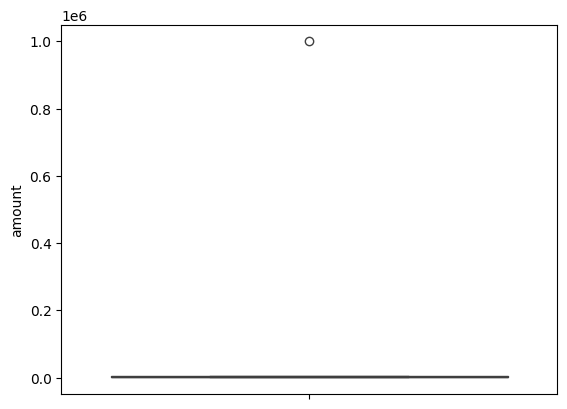

In [70]:
sns.boxplot(df["amount"])

In [71]:
df.loc[df["amount_suspicious"], "amount"] = np.nan

In [72]:
df["source"].value_counts()

source
instagram          760
facebook           760
friend/relative    743
telegram           741
unknown              1
Name: count, dtype: int64

In [73]:
df.drop(df[df["source"] == "unknown"].index, inplace = True)

In [74]:
df["source"].value_counts()

source
instagram          760
facebook           760
friend/relative    743
telegram           741
Name: count, dtype: int64

In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3004 entries, 0 to 3005
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   deal_id            3004 non-null   int64  
 1   customer_id        3004 non-null   int64  
 2   amount             3002 non-null   float64
 3   source             3004 non-null   object 
 4   status             3004 non-null   object 
 5   amount_missing     3004 non-null   bool   
 6   amount_suspicious  3004 non-null   bool   
 7   city               3004 non-null   object 
 8   age                3004 non-null   int64  
dtypes: bool(2), float64(1), int64(3), object(3)
memory usage: 193.6+ KB


In [76]:
df[df["amount"].isna()] 

,deal_id,customer_id,amount,source,status,amount_missing,amount_suspicious,city,age
3002,3003,76,NaN,facebook,lost,True,False,Vagharshapat,60
3004,3006,90,NaN,friend/relative,won,False,True,Yerevan,35


In [77]:
df.drop(df[df["amount"].isna()].index, inplace = True)

In [78]:
df[df["amount"].isna()] 

,deal_id,customer_id,amount,source,status,amount_missing,amount_suspicious,city,age


In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3002 entries, 0 to 3005
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   deal_id            3002 non-null   int64  
 1   customer_id        3002 non-null   int64  
 2   amount             3002 non-null   float64
 3   source             3002 non-null   object 
 4   status             3002 non-null   object 
 5   amount_missing     3002 non-null   bool   
 6   amount_suspicious  3002 non-null   bool   
 7   city               3002 non-null   object 
 8   age                3002 non-null   int64  
dtypes: bool(2), float64(1), int64(3), object(3)
memory usage: 193.5+ KB


In [80]:
numeric_features = ["amount", "age"]
categorical_features = ["source", "city"]

In [81]:
X = df[numeric_features + categorical_features].copy()
y = df["status"]

In [82]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=df["customer_id"]))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

In [83]:
preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric_features),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features)  ])

## Benchmark Model

In [84]:
model = DummyClassifier(strategy="most_frequent")

In [85]:
pipe = Pipeline([("preprocessing", preprocess), ("model", model)])

In [86]:
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['in progress','lost','won']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['amount','age','source','city']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining column

In [87]:
y_pred = pipe.predict(X_test)

In [88]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.3401360544217687

Classification Report:
              precision    recall  f1-score   support

 in progress       0.34      1.00      0.51       200
        lost       0.00      0.00      0.00       182
         won       0.00      0.00      0.00       206

    accuracy                           0.34       588
   macro avg       0.11      0.33      0.17       588
weighted avg       0.12      0.34      0.17       588


Confusion Matrix:
[[200   0   0]
 [182   0   0]
 [206   0   0]]


## Logistic Regression

In [89]:
model = LogisticRegression(max_iter=1000)

In [90]:
pipe = Pipeline([("preprocessing", preprocess), ("model", model)])

In [91]:
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['in progress','lost','won']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['amount','age','source','city']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining column

In [92]:
y_pred = pipe.predict(X_test)

In [93]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.3469387755102041

Classification Report:
              precision    recall  f1-score   support

 in progress       0.37      0.42      0.39       200
        lost       0.31      0.31      0.31       182
         won       0.36      0.31      0.33       206

    accuracy                           0.35       588
   macro avg       0.35      0.35      0.34       588
weighted avg       0.35      0.35      0.35       588


Confusion Matrix:
[[84 59 57]
 [68 56 58]
 [76 66 64]]


### Hyperparameter Tuning

In [94]:
logreg_param_grid = {
        "model__solver": ["lbfgs"],
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]}

In [95]:
logreg_grid = GridSearchCV(
    estimator = Pipeline([("preprocessing", preprocess), ("model", LogisticRegression(max_iter=2000, random_state=42))]),
    param_grid = logreg_param_grid,
    scoring = "accuracy",
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs = -1,
)

In [96]:
logreg_grid.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced'], 'model__solver': ['lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",

In [97]:
print("Best params:", logreg_grid.best_params_)
print("Best CV accuracy:", logreg_grid.best_score_)


Best params: {'model__C': 1, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Best CV accuracy: 0.3276668127110126


In [98]:
best_logreg = logreg_grid.best_estimator_
y_pred = best_logreg.predict(X_test)


In [99]:
print("\nTest Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Test Accuracy: 0.34523809523809523

Classification Report:
              precision    recall  f1-score   support

 in progress       0.38      0.30      0.34       200
        lost       0.30      0.32      0.31       182
         won       0.36      0.41      0.38       206

    accuracy                           0.35       588
   macro avg       0.35      0.34      0.34       588
weighted avg       0.35      0.35      0.34       588


Confusion Matrix:
[[61 68 71]
 [46 58 78]
 [54 68 84]]


## RandomForest

In [100]:
model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)

In [101]:
pipe = Pipeline([("preprocessing", preprocess), ("model", model)])

In [102]:
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['in progress','lost','won']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['amount','age','source','city']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining column

In [103]:
y_pred = pipe.predict(X_test)

In [104]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.3197278911564626

Classification Report:
              precision    recall  f1-score   support

 in progress       0.32      0.42      0.36       200
        lost       0.30      0.31      0.30       182
         won       0.36      0.23      0.28       206

    accuracy                           0.32       588
   macro avg       0.32      0.32      0.32       588
weighted avg       0.32      0.32      0.32       588


Confusion Matrix:
[[84 69 47]
 [86 56 40]
 [95 63 48]]


### Hyperparameter Tuning

In [105]:
rf_param_dist = {
    "model__n_estimators": randint(100, 600),
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": randint(1, 20),
    "model__min_samples_split": randint(2, 20),
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": [None, "balanced"],
}

In [106]:

rf_search = RandomizedSearchCV(
    estimator = Pipeline([("preprocessing", preprocess), ("model", RandomForestClassifier(random_state=42, n_jobs=-1))]),
    param_distributions = rf_param_dist,
    n_iter = 40,
    scoring = "accuracy",
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state = 42,
    n_jobs = -1,)

In [107]:
rf_search.fit(X_train, y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [3, 4, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': <scipy.stats....0019667C0C810>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute 

In [108]:
print("Best params:", rf_search.best_params_)
print("Best CV accuracy:", rf_search.best_score_)

Best params: {'model__class_weight': 'balanced', 'model__max_depth': 3, 'model__max_features': None, 'model__min_samples_leaf': 9, 'model__min_samples_split': 9, 'model__n_estimators': 367}
Best CV accuracy: 0.3521111998831645


In [109]:
best_rf = rf_search.best_estimator_
y_pred = best_rf.predict(X_test)

In [110]:
print("\nTest Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Test Accuracy: 0.34523809523809523

Classification Report:
              precision    recall  f1-score   support

 in progress       0.37      0.55      0.44       200
        lost       0.29      0.17      0.21       182
         won       0.34      0.30      0.32       206

    accuracy                           0.35       588
   macro avg       0.33      0.34      0.33       588
weighted avg       0.33      0.35      0.33       588


Confusion Matrix:
[[110  32  58]
 [ 91  31  60]
 [ 99  45  62]]


## Baseline vs Tuned Comparison

In [111]:
baseline_dummy = Pipeline([("preprocessing", preprocess), ("model", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
baseline_logreg = Pipeline([("preprocessing", preprocess), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
baseline_rf = Pipeline([("preprocessing", preprocess), ("model", RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1))]).fit(X_train, y_train)

results = pd.DataFrame({
    "model": [
        "Dummy (baseline)",
        "Logistic Regression (baseline)", "Logistic Regression (tuned)",
        "Random Forest (baseline)", "Random Forest (tuned)",
    ],
    "test_accuracy": [
        accuracy_score(y_test, baseline_dummy.predict(X_test)),
        accuracy_score(y_test, baseline_logreg.predict(X_test)),
        accuracy_score(y_test, best_logreg.predict(X_test)),
        accuracy_score(y_test, baseline_rf.predict(X_test)),
        accuracy_score(y_test, best_rf.predict(X_test)),
    ],
})

results.sort_values("test_accuracy", ascending=False).reset_index(drop=True)

,model,test_accuracy
0,Logistic Regression (baseline),0.346939
1,Random Forest (tuned),0.345238
2,Logistic Regression (tuned),0.345238
3,Dummy (baseline),0.340136
4,Random Forest (baseline),0.319728
